# 10 · Cell–cell communication

Fibrosis is driven by crosstalk: injured epithelium and macrophages produce
signals (TGF-β activation, SPP1, PDGF, WNT ...) that activate fibroblasts.
Ligand–receptor (LR) inference estimates which of these signals are
*possible* given expression, using curated LR resources.

* **LIANA** (Dimitrov *et al.* 2022, *Nat Commun*) runs several methods
  (CellPhoneDB, Connectome, log2FC, NATMI, SingleCellSignalR, CellChat-like
  geometric means) on the same **consensus** resource (OmniPath-derived, with
  heteromeric complexes) and aggregates their ranks with robust rank
  aggregation; `magnitude_rank` (strength) and `specificity_rank` (how
  specific to the cell-type pair) are reported.
* **Differential communication** (LIANA+ `df_to_lr`; Dimitrov *et al.* 2024
  *Nat Cell Biol*) combines the **donor-level pseudobulk DE statistics** of
  ligands in sender cells and receptors in receiver cells, so changes are
  supported by replicate-aware statistics (Notebook 07) rather than by
  cell-level tests.

**Caveat.** LR inference predicts potential interactions from mRNA; protein
abundance, ligand processing (e.g. latent TGF-β activation) and spatial
proximity are not observed. Results are hypotheses.

In [1]:
import liana as li
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns

from ipfatlas.config import setup
from ipfatlas.plotting import figsize, panel_label, save_figure, set_style
from ipfatlas.utils import timer, write_table

cfg, P = setup()
set_style(cfg["figures"]["font_size"])
FIG = P.figures / "10_communication"
TAB = P.tables / "10_communication"
C = cfg["communication"]
CAP = 1500  # cells per cell type and condition (equalises power between conditions)

full = sc.read_h5ad(P.processed / "discovery_annotated.h5ad")
full = full[full.obs["diagnosis"].isin(["Control", "IPF"])].copy()
colors = dict(zip(full.obs["cell_type"].cat.categories, full.uns["cell_type_colors"]))

## 1. LIANA rank aggregate per condition
The same number of cells per type is drawn in each condition so that the
number of detected interactions is not driven by cell numbers.

In [2]:
rng = np.random.default_rng(0)
res = {}
for dx in ["Control", "IPF"]:
    idx = []
    for ct in full.obs["cell_type"].cat.categories:
        cells = np.where((full.obs["cell_type"] == ct) & (full.obs["diagnosis"] == dx))[0]
        if len(cells) >= 20:
            idx.extend(rng.choice(cells, min(CAP, len(cells)), replace=False))
    sub = full[np.sort(idx)].copy()
    sub.obs["cell_type"] = sub.obs["cell_type"].cat.remove_unused_categories()
    with timer(f"LIANA {dx} ({sub.n_obs:,} cells)"):
        li.mt.rank_aggregate(sub, groupby="cell_type", resource_name=C["resource"], expr_prop=C["min_expr_prop"],
                             use_raw=False, n_perms=C["n_perms"], seed=0, verbose=False)
    r = sub.uns["liana_res"].copy()
    r["condition"] = dx
    res[dx] = r
    write_table(r[r["magnitude_rank"] <= 0.05], TAB / f"liana_rank_aggregate_{dx}", index=False)
del sub

04:57:12 | INFO | LIANA Control (23,709 cells) ...


LIANA Control (23,709 cells) ...


J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\liana\method\_pipe_utils\_pre.py:164: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.


J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\liana\method\_pipe_utils\_pre.py:167: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\liana\method\sc\_liana_pipe.py:288: ImplicitModificationWarning: Setting element `.layers['scaled']` of view, initializing view as actual.


J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\liana\method\sc\_liana_pipe.py:293: FutureWarning: The method uns_keys is deprecated and will be removed in the future. Use uns instead of uns_keys. (e.g. `k in adata.uns` or `sorted(adata.uns)`)
J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\liana\method\sc\_liana_pipe.py:296: FutureWarning: The method uns_keys is deprecated and will be removed in the future. Use uns instead of uns_keys. (e.g. `k in adata.uns` or `sorted(adata.uns)`)


... (6 outputs left out)

J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\liana\method\sc\_liana_pipe.py:288: ImplicitModificationWarning: Setting element `.layers['scaled']` of view, initializing view as actual.


J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\liana\method\sc\_liana_pipe.py:293: FutureWarning: The method uns_keys is deprecated and will be removed in the future. Use uns instead of uns_keys. (e.g. `k in adata.uns` or `sorted(adata.uns)`)
J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\liana\method\sc\_liana_pipe.py:296: FutureWarning: The method uns_keys is deprecated and will be removed in the future. Use uns instead of uns_keys. (e.g. `k in adata.uns` or `sorted(adata.uns)`)


05:01:50 | INFO | LIANA IPF (33,885 cells) done in 147.0 s


LIANA IPF (33,885 cells) done in 147.0 s


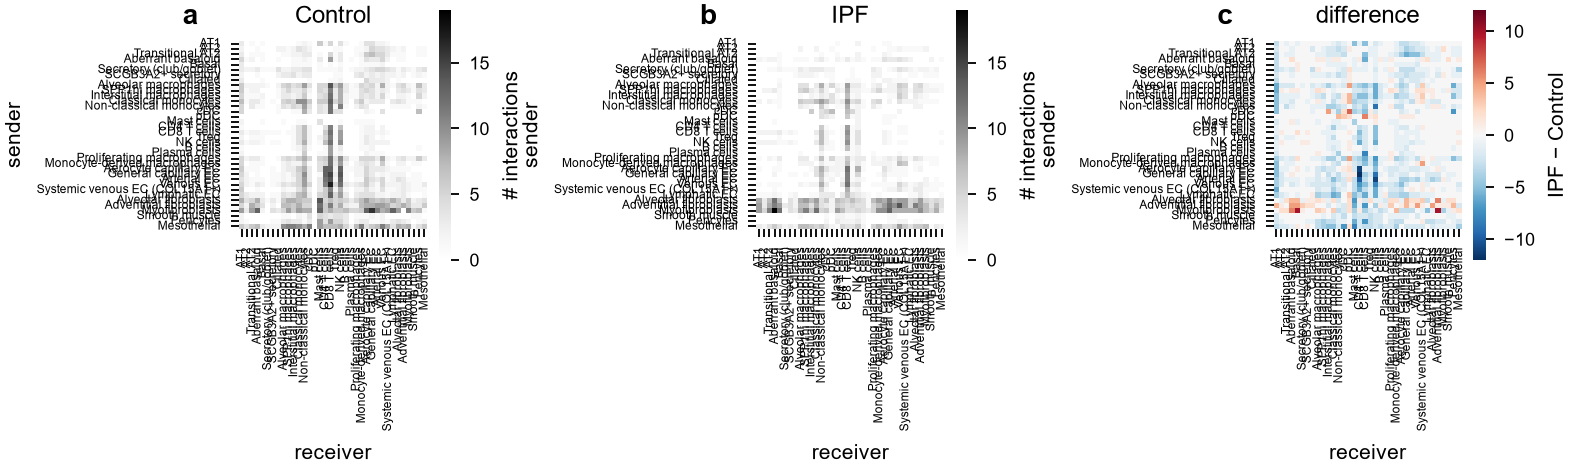

In [3]:
def n_sig(r, thr=0.01):
    s = r[(r["magnitude_rank"] <= thr) & (r["specificity_rank"] <= 0.05)]
    return s.groupby(["source", "target"]).size().unstack(fill_value=0)


cts = list(full.obs["cell_type"].cat.categories)
mats = {dx: n_sig(res[dx]).reindex(index=cts, columns=cts, fill_value=0) for dx in res}
diff = mats["IPF"] - mats["Control"]
write_table(diff, TAB / "n_interactions_IPF_minus_Control")

fig, axes = plt.subplots(1, 3, figsize=figsize(183, 70))
vmax = max(m.values.max() for m in mats.values())
for ax, dx in zip(axes[:2], ["Control", "IPF"]):
    sns.heatmap(mats[dx], cmap="Greys", vmin=0, vmax=vmax, ax=ax, cbar_kws={"label": "# interactions", "shrink": 0.6},
                xticklabels=True, yticklabels=True, square=True)
    ax.set_title(dx)
lim = np.abs(diff.values).max()
sns.heatmap(diff, cmap="RdBu_r", center=0, vmin=-lim, vmax=lim, ax=axes[2], square=True,
            cbar_kws={"label": "IPF − Control", "shrink": 0.6}, xticklabels=True, yticklabels=True)
axes[2].set_title("difference")
for ax in axes:
    ax.tick_params(labelsize=4)
    ax.set_xlabel("receiver")
    ax.set_ylabel("sender")
for a, l in zip(axes, "abc"):
    panel_label(a, l, x=-0.3)
fig.tight_layout()
save_figure(fig, "S10_interaction_counts", FIG)
plt.show()

## 2. Differential communication from pseudobulk DE (IPF vs control)
For every sender → receiver pair: ligand statistic in the sender and receptor
statistic in the receiver (signed edgeR √F, Notebook 07); `interaction_stat` is
their mean. Interactions are kept when both partners are expressed in ≥10 % of
cells of their cell type (in IPF lungs).

In [4]:
edger = pd.read_csv(P.tables / "07_de" / "edgeR_IPF_vs_control_all_celltypes.csv.gz")
dea = edger.rename(columns={"PValue": "pvalue", "FDR": "padj"}).set_index("gene")[
    ["celltype", "stat", "logFC", "pvalue", "padj"]].rename(columns={"celltype": "cell_type"})
ipf = full[full.obs["diagnosis"] == "IPF"].copy()
ipf = ipf[ipf.obs["cell_type"].isin(dea["cell_type"].unique())].copy()
ipf.obs["cell_type"] = ipf.obs["cell_type"].cat.remove_unused_categories()
with timer("df_to_lr"):
    lr = li.multi.df_to_lr(ipf, dea_df=dea, groupby="cell_type", stat_keys=["stat", "logFC", "pvalue", "padj"],
                           resource_name=C["resource"], expr_prop=C["min_expr_prop"], use_raw=False,
                           complex_col="stat", return_all_lrs=False)
lr = lr.sort_values("interaction_stat", ascending=False)
write_table(lr, TAB / "differential_lr_pseudobulk", index=False)
lr.head(20)

05:02:00 | INFO | df_to_lr ...


df_to_lr ...


J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\liana\method\_pipe_utils\_pre.py:164: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.


J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\liana\method\_pipe_utils\_pre.py:167: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


05:02:15 | INFO | df_to_lr done in 15.5 s


df_to_lr done in 15.5 s


,ligand,receptor,ligand_complex,receptor_complex,source,ligand_stat,ligand_logFC,ligand_pvalue,ligand_padj,ligand_expr,...,receptor_padj,receptor_expr,receptor_props,interaction_stat,interaction_logFC,interaction_pvalue,interaction_padj,interaction_expr,interaction_props,interaction
1157,MMP7,CD44,MMP7,CD44,AT1,9.791891,7.319675,1.297888e-11,4.315477e-08,0.390534,...,0.001136,0.139279,0.245033,8.156753,4.924587,5.127486e-07,0.000568,0.264906,0.243241,MMP7^CD44
7673,MMP7,CD44,MMP7,CD44,AT1,9.791891,7.319675,1.297888e-11,4.315477e-08,0.390534,...,0.020631,0.440804,0.363014,7.292527,6.194415,4.783838e-05,0.010315,0.415669,0.302231,MMP7^CD44
44130,SPP1,CD44,SPP1,CD44,Alveolar macrophages,7.216150,7.876575,2.000214e-07,7.030752e-04,0.317934,...,0.001136,0.139279,0.245033,6.868882,5.203037,6.127528e-07,0.000920,0.228607,0.200550,SPP1^CD44
17000,FBLN1,ITGB1,FBLN1,ITGB1,Transitional AT2,9.816349,6.688154,6.993790e-08,3.451436e-04,0.150447,...,0.041639,0.529014,0.742270,6.853133,3.697817,3.525841e-04,0.020992,0.339730,0.481679,FBLN1^ITGB1
5198,MMP7,CD44,MMP7,CD44,AT1,9.791891,7.319675,1.297888e-11,4.315477e-08,0.390534,...,0.030768,1.255829,0.879357,6.773471,4.007860,4.447360e-04,0.015384,0.823181,0.560403,MMP7^CD44
8362,TGFB1,ITGB8,TGFB1,ITGB8,AT2,6.684303,2.941856,1.746474e-07,1.612227e-04,0.068319,...,0.001618,0.077573,0.149660,6.742547,3.885527,2.221912e-06,0.000890,0.072946,0.131555,TGFB1^ITGB8
2340,MMP7,CD44,MMP7,CD44,AT1,9.791891,7.319675,1.297888e-11,4.315477e-08,0.390534,...,0.084910,1.138566,0.864533,6.702013,4.135209,6.233780e-04,0.042455,0.764550,0.552991,MMP7^CD44
1192,MMP7,SDC1,MMP7,SDC1,AT1,9.791891,7.319675,1.297888e-11,4.315477e-08,0.390534,...,0.021466,0.337226,0.514116,6.701821,4.073531,7.508400e-04,0.010733,0.363880,0.377783,MMP7^SDC1
20631,FBLN1,ITGB1,FBLN1,ITGB1,Transitional AT2,9.816349,6.688154,6.993790e-08,3.451436e-04,0.150447,...,0.045611,0.571485,0.640194,6.646319,3.649436,9.065320e-04,0.022978,0.360966,0.430641,FBLN1^ITGB1
17120,PLAU,ITGAM,PLAU,ITGAM,Transitional AT2,7.779751,7.894822,9.365631e-06,2.505959e-03,0.126391,...,0.005165,0.215328,0.384043,6.630994,4.580356,1.105002e-05,0.003835,0.170860,0.283858,PLAU^ITGAM


In [5]:
up = lr[(lr["ligand_padj"] < 0.05) & (lr["receptor_padj"] < 0.05) & (lr["ligand_stat"] > 0) & (lr["receptor_stat"] > 0)]
down = lr[(lr["ligand_padj"] < 0.05) & (lr["receptor_padj"] < 0.05) & (lr["ligand_stat"] < 0) & (lr["receptor_stat"] < 0)]
print(f"{len(up)} interactions with ligand and receptor both up in IPF; {len(down)} both down")
write_table(up, TAB / "differential_lr_both_up", index=False)
write_table(down, TAB / "differential_lr_both_down", index=False)

602 interactions with ligand and receptor both up in IPF; 8 both down


WindowsPath('J:/Portfolio_projects/Projects/scRNA/results/tables/10_communication/differential_lr_both_down.csv')

### Signals received by fibroblasts and myofibroblasts
Fibroblast activation is the effector step of fibrosis, so we focus on the
interactions *received* by mesenchymal cells.

J:\Portfolio_projects\Projects\scRNA\.cache\tmp\ipykernel_53728\2705775601.py:22: UserWarning: Glyph 8733 (\N{PROPORTIONAL TO}) missing from font(s) Arial.
J:\Portfolio_projects\Projects\scRNA\src\ipfatlas\plotting.py:114: UserWarning: Glyph 8733 (\N{PROPORTIONAL TO}) missing from font(s) Arial.
J:\Portfolio_projects\Projects\scRNA\src\ipfatlas\plotting.py:114: UserWarning: Glyph 8733 (\N{PROPORTIONAL TO}) missing from font(s) Arial.
J:\Portfolio_projects\Projects\scRNA\src\ipfatlas\plotting.py:114: UserWarning: Glyph 8733 (\N{PROPORTIONAL TO}) missing from font(s) Arial.


J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8733 (\N{PROPORTIONAL TO}) missing from font(s) Arial.


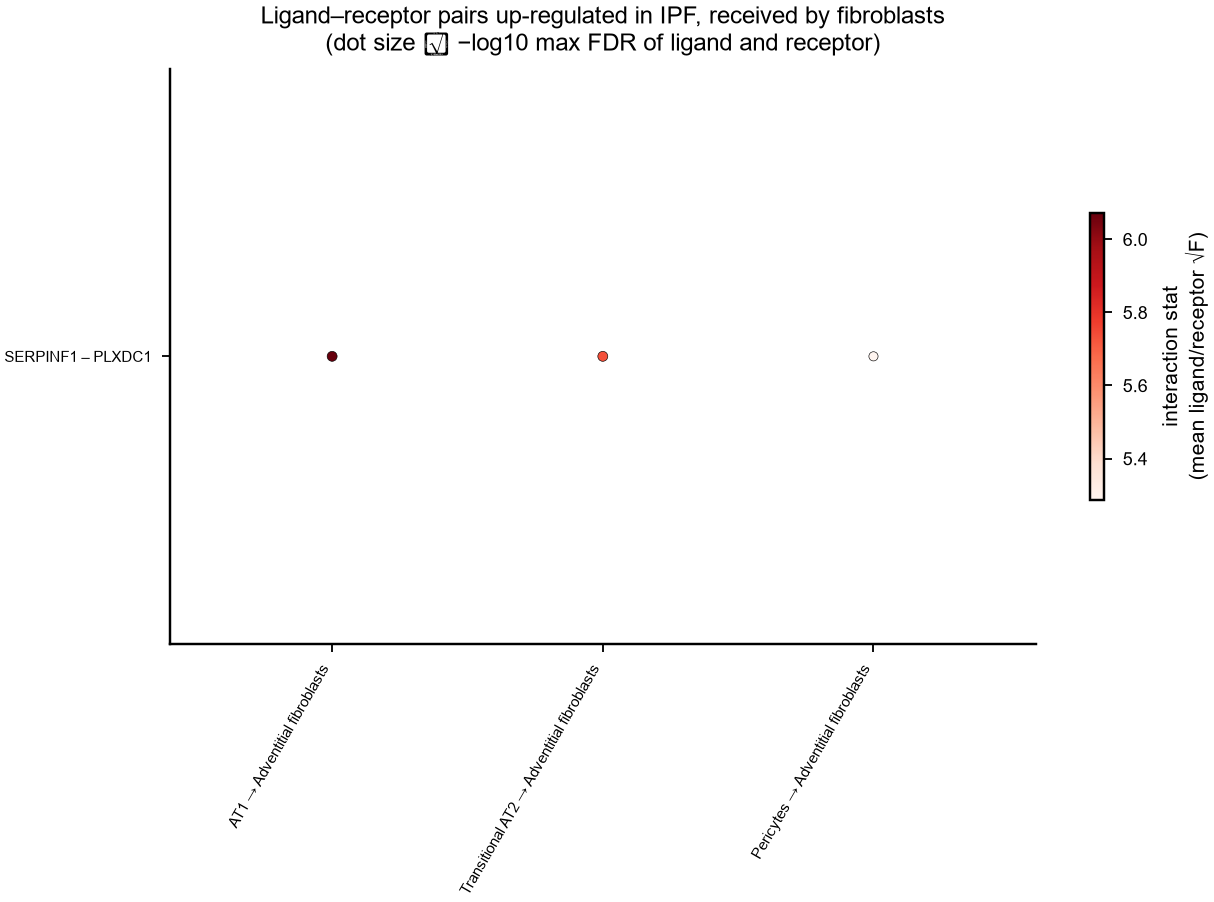

In [6]:
mes_targets = [c for c in ["Myofibroblasts", "Alveolar fibroblasts", "Adventitial fibroblasts"] if c in lr["target"].unique()]
foc = up[up["target"].isin(mes_targets)].copy()
foc["pair"] = foc["source"] + " → " + foc["target"]
foc["lr"] = foc["ligand_complex"] + " – " + foc["receptor_complex"]
top_lr = foc.groupby("lr")["interaction_stat"].max().nlargest(25).index
top_pairs = foc[foc["lr"].isin(top_lr)].groupby("pair")["interaction_stat"].max().nlargest(14).index
d = foc[foc["lr"].isin(top_lr) & foc["pair"].isin(top_pairs)]

fig, ax = plt.subplots(figsize=figsize(150, 110))
xcat = {p: i for i, p in enumerate(top_pairs)}
ycat = {p: i for i, p in enumerate(top_lr[::-1])}
sca = ax.scatter(d["pair"].map(xcat), d["lr"].map(ycat), c=d["interaction_stat"], cmap="Reds",
                 s=4 + 30 * (-np.log10(d[["ligand_padj", "receptor_padj"]].max(axis=1).clip(1e-10)) / 10),
                 edgecolor="black", linewidth=0.2)
ax.set_xticks(range(len(xcat)), list(xcat), rotation=60, ha="right", fontsize=5)
ax.set_yticks(range(len(ycat)), list(ycat), fontsize=5)
ax.set_xlim(-0.6, len(xcat) - 0.4)
ax.set_ylim(-0.6, len(ycat) - 0.4)
plt.colorbar(sca, ax=ax, shrink=0.5, label="interaction stat\n(mean ligand/receptor √F)")
ax.set_title("Ligand–receptor pairs up-regulated in IPF, received by fibroblasts\n"
             "(dot size ∝ −log10 max FDR of ligand and receptor)")
fig.tight_layout()
save_figure(fig, "Fig5_differential_lr_fibroblast_targets", FIG)
plt.show()

### Candidate pro-fibrotic axes
Literature-motivated axes checked explicitly (whether or not they rank at the top):
integrin αvβ6 (ITGB6, epithelium) - activates latent TGF-β (Munger *et al.* 1999);
SPP1 (macrophages) → CD44/integrins on fibroblasts (Morse *et al.* 2019);
PDGFB → PDGFRB; WNT5A/WNT2 → FZD; CTGF/CCN2.

In [7]:
axes_of_interest = ["SPP1", "TGFB1", "TGFB2", "PDGFB", "PDGFA", "WNT5A", "WNT2", "CCN2", "POSTN", "COL1A1", "FN1",
                    "MDK", "CXCL12", "ANGPTL4"]
cand = lr[lr["ligand_complex"].isin(axes_of_interest) & (lr["ligand_padj"] < 0.05)]
cand = cand.sort_values("interaction_stat", ascending=False).drop_duplicates(["ligand_complex", "receptor_complex", "source"])
write_table(cand, TAB / "candidate_profibrotic_axes", index=False)
cand[["source", "target", "ligand_complex", "receptor_complex", "ligand_stat", "receptor_stat", "interaction_stat"]].head(30)

,source,target,ligand_complex,receptor_complex,ligand_stat,receptor_stat,interaction_stat
44130,Alveolar macrophages,Secretory (club/goblet),SPP1,CD44,7.216150,6.521614,6.868882
8362,AT2,Transitional AT2,TGFB1,ITGB8,6.684303,6.800792,6.742547
108504,Monocyte-derived macrophages,Secretory (club/goblet),FN1,CD44,5.141755,6.521614,5.831684
45912,Alveolar macrophages,Classical monocytes,SPP1,ITGAV_ITGB5,7.216150,4.395931,5.806040
45913,Alveolar macrophages,Classical monocytes,SPP1,ITGAV_ITGB6,7.216150,4.395931,5.806040
44089,Alveolar macrophages,Secretory (club/goblet),FN1,CD44,5.081201,6.521614,5.801408
142891,Systemic venous EC (COL15A1+),Secretory (club/goblet),SPP1,CD44,4.818939,6.521614,5.670276
15492,Transitional AT2,Transitional AT2,TGFB1,ITGB8,4.519104,6.800792,5.659948
169158,Adventitial fibroblasts,Alveolar macrophages,CXCL12,CD4,5.982733,5.185116,5.583924
44949,Alveolar macrophages,Alveolar macrophages,SPP1,ITGA9_ITGB1,7.216150,3.889917,5.553034


## 3. Sender/receiver summary
Summed positive interaction statistic of significant up-regulated interactions,
per sender and per receiver cell type.

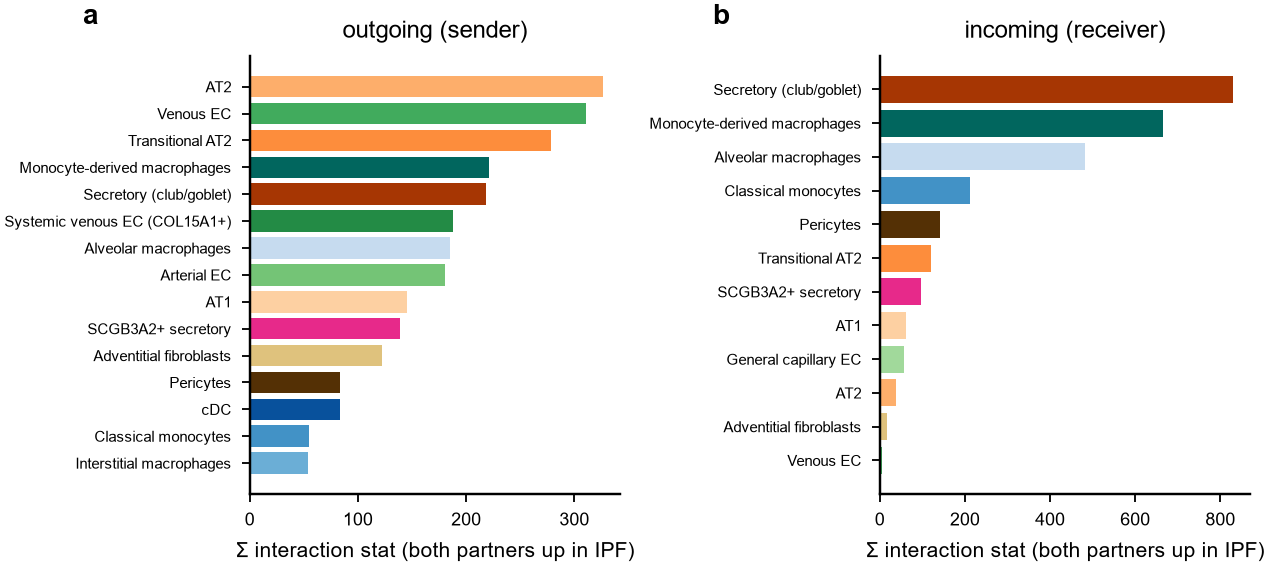

In [8]:
send = up.groupby("source")["interaction_stat"].sum().sort_values()
recv = up.groupby("target")["interaction_stat"].sum().sort_values()
fig, axes = plt.subplots(1, 2, figsize=figsize(150, 70))
for ax, s, t in [(axes[0], send, "outgoing (sender)"), (axes[1], recv, "incoming (receiver)")]:
    s = s.tail(15)
    ax.barh(range(len(s)), s.values, color=[colors.get(c, "grey") for c in s.index])
    ax.set_yticks(range(len(s)), s.index, fontsize=5)
    ax.set_xlabel("Σ interaction stat (both partners up in IPF)")
    ax.set_title(t)
for a, l in zip(axes, "ab"):
    panel_label(a, l, x=-0.45)
fig.tight_layout()
save_figure(fig, "Fig5_sender_receiver_summary", FIG)
plt.show()